In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load the dataset
df = pd.read_csv('./data/customer_support_clean.csv')

In [2]:
sample = df.iloc[100]
print("=== Sample Conversation ===")
#print(f"Conversation ID: {sample['conversation_id']}")
print(f"Model used: {sample['model_used']}")
print(f"Latency: {sample['latency_seconds']:.2f}s")
print(f"Tokens used: {sample['tokens_used']}")
print(f"Cost: ${sample['cost']:.4f}")
print(f"Resolved: {sample['resolved']}")
print(f"CSAT: {sample['csat_score']}/5")
print(f"Hallucinated: {sample['hallucinated']}")
print(f"Instruction: {sample['instruction']}")
print(f"Response: {sample['response'][0:100]}...")

=== Sample Conversation ===
Model used: gpt-4
Latency: 2.78s
Tokens used: 194
Cost: $0.0058
Resolved: True
CSAT: 3.1/5
Hallucinated: False
Instruction: where can I cancel order {{Order Number}}?
Response: I've taken note that you're looking for information on where to cancel order {{Order Number}}. You c...


In [ ]:
# Calculate latency metrics
avg_latency = df['latency_seconds'].mean()
p95_latency =  df['latency_seconds'].quantile(0.95)
p99_latency = df['latency_seconds'].quantile(0.99)

# Count slow conversations (>5 seconds)
slow_conversations = df[df['latency_seconds'] > 5].shape[0]
slow_percentage = (slow_conversations / df.shape[0]) * 100

# Display results
print("=== Performance Metrics ===")
print(f"Average latency: {avg_latency:.2f}s")
print(f"p95 latency: {p95_latency:.2f}s")
print(f"p99 latency: {p99_latency:.2f}s")
print(f"\nSlow conversations (>5s): {slow_conversations} ({slow_percentage:.1f}%)")

=== Performance Metrics ===
Average latency: 2.11s
p95 latency: 3.12s
p99 latency: 3.51s

Slow conversations (>5s): 0 (0.0%)


In [ ]:
# Quality metrics
resolution_rate = df['resolved'].mean()
hallucination_rate = df['hallucinated'].mean()
avg_csat = df['csat_score'].mean()
escalation_rate = df['escalated_to_human'].mean()

# Cost metrics
total_cost = df['cost'].sum()
avg_cost = df['cost'].mean()
total_tokens = df['tokens_used'].sum()
yearly_projection = total_cost * 12

# Display results
print("=== Quality Metrics ===")
print(f"Resolution rate: {resolution_rate:.1%}")
print(f"Hallucination rate: {hallucination_rate:.1%}")
print(f"Average CSAT: {avg_csat:.2f}/5")
print(f"Escalation rate: {escalation_rate:.1%}")

print("\n=== Cost Metrics ===")
print(f"Total cost (today): ${total_cost:.2f}")
print(f"Average per conversation: ${avg_cost:.4f}")
print(f"Total tokens: {total_tokens:,}")
print(f"Yearly projection: ${yearly_projection:,.2f}")

=== Quality Metrics ===
Resolution rate: 73.1%
Hallucination rate: 8.2%
Average CSAT: 4.05/5
Escalation rate: 8.2%

=== Cost Metrics ===
Total cost (today): $91.16
Average per conversation: $0.0034
Total tokens: 4,664,692
Yearly projection: $1,093.89


=== Weekly Trend Analysis ===
Worst performing week: Week 3 (72.5% resolution)

First week → Last week changes:
Resolution rate: -0.6%
CSAT score: +0.01
Latency: -0.02s


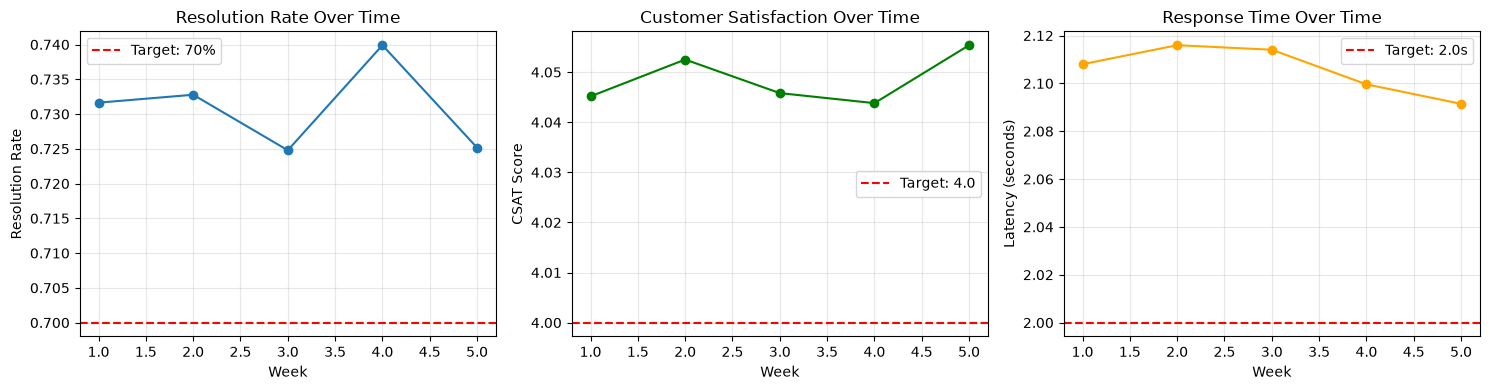

In [5]:
# Group by week and calculate metrics
weekly_metrics = df.groupby('week_number', sort=True).agg({
    'resolved': 'mean',
    'csat_score': 'mean',
    'latency_seconds': 'mean'
}).reset_index()

# Rename columns for clarity
weekly_metrics.columns = ['week', 'resolution_rate', 'avg_csat', 'avg_latency']

# Find worst performing week
worst_week_idx = int(weekly_metrics['resolution_rate'].argmin())
worst_week = weekly_metrics['week'].iloc[worst_week_idx]
worst_resolution = weekly_metrics['resolution_rate'].iloc[worst_week_idx]

# Calculate changes from first to last week
first_week = weekly_metrics.iloc[0]
last_week = weekly_metrics.iloc[-1]

resolution_change = last_week['resolution_rate'] - first_week['resolution_rate']
csat_change = last_week['avg_csat'] - first_week['avg_csat']
latency_change = last_week['avg_latency'] - first_week['avg_latency']

# Display summary
print("=== Weekly Trend Analysis ===")
print(f"Worst performing week: Week {worst_week} ({worst_resolution:.1%} resolution)")
print(f"\nFirst week → Last week changes:")
print(f"Resolution rate: {resolution_change:+.1%}")
print(f"CSAT score: {csat_change:+.2f}")
print(f"Latency: {latency_change:+.2f}s")

# Create visualization
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# Plot 1: Resolution Rate
axes[0].plot(weekly_metrics['week'], weekly_metrics['resolution_rate'], marker='o')
axes[0].axhline(y=0.70, color='r', linestyle='--', label='Target: 70%')
axes[0].set_xlabel('Week')
axes[0].set_ylabel('Resolution Rate')
axes[0].set_title('Resolution Rate Over Time')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Plot 2: CSAT Score
axes[1].plot(weekly_metrics['week'], weekly_metrics['avg_csat'], marker='o', color='green')
axes[1].axhline(y=4.0, color='r', linestyle='--', label='Target: 4.0')
axes[1].set_xlabel('Week')
axes[1].set_ylabel('CSAT Score')
axes[1].set_title('Customer Satisfaction Over Time')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

# Plot 3: Latency
axes[2].plot(weekly_metrics['week'], weekly_metrics['avg_latency'],  marker='o', color='orange')
axes[2].axhline(y=2.0, color='r', linestyle='--', label='Target: 2.0s')
axes[2].set_xlabel('Week')
axes[2].set_ylabel('Latency (seconds)')
axes[2].set_title('Response Time Over Time')
axes[2].legend()
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()